# EcoSort AI: preprocessing and data splits (notebook 02)

This notebook creates a reproducible, **group-aware** 70/15/15 train/validation/test split. It uses the `group_id` values produced by notebook 01 so perceptually similar images stay in the same split.

Run notebook 01 first. It downloads the dataset, checks image quality, creates perceptual groups, and saves `manifest.csv`.

Outputs are saved under the persistent `ecosort/` project folder in Google Drive by default.


In [1]:
import os, json, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf

# ---- Configuration -------------------------------------------------------
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15
N_SPLITS = 20  # 14 folds train, 3 validation, 3 test = 70/15/15 approximately

USE_DRIVE = True  # Set False only for a temporary local runtime
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/ecosort")
else:
    BASE_DIR = Path(".")
BASE_DIR.mkdir(parents=True, exist_ok=True)

RAW_DIR = BASE_DIR / "data_raw"
SPLIT_DIR = BASE_DIR / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = BASE_DIR / "manifest.csv"
URL = "https://archive.ics.uci.edu/static/public/908/realwaste.zip"

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"{MANIFEST_PATH} not found. Run notebook 01_download_and_inspect first; "
        "it creates the manifest and perceptual duplicate groups."
    )

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__)
print("Project directory:", BASE_DIR)


Mounted at /content/drive
TensorFlow 2.21.0
Project directory: /content/drive/MyDrive/ecosort


## 1. Make sure the data is present
Skips the download if `data_raw/` already exists. If the download fails, download the zip manually from https://archive.ics.uci.edu/dataset/908/realwaste and unzip it into `data_raw/`.

In [2]:
if not RAW_DIR.exists():
    req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
    zip_path = BASE_DIR / "realwaste.zip"
    with urllib.request.urlopen(req) as r, open(zip_path, "wb") as f:
        f.write(r.read())
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(RAW_DIR)

def find_class_root(base: Path) -> Path:
    for p in base.rglob("*"):
        if p.is_dir() and p.name == "RealWaste" and any(d.is_dir() for d in p.iterdir()):
            return p
    raise FileNotFoundError("Could not find a RealWaste folder with class subfolders")

DATA_DIR = find_class_root(RAW_DIR)
print("Data dir:", DATA_DIR)

Data dir: /content/drive/MyDrive/ecosort/data_raw/realwaste-main/RealWaste


## 2. List every image and encode labels

Labels are sorted alphabetically and saved so the order is identical in training, the API, and the dashboard. The image list is joined to the manifest from notebook 01 to retrieve perceptual group IDs.


In [3]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
class_names = sorted(d.name for d in DATA_DIR.iterdir() if d.is_dir())
class_to_idx = {c: i for i, c in enumerate(class_names)}

rows = []
for cls in class_names:
    for p in sorted((DATA_DIR / cls).iterdir()):
        if p.suffix.lower() in IMG_EXT:
            rows.append({"path": f"{cls}/{p.name}", "class": cls, "label": class_to_idx[cls]})
df = pd.DataFrame(rows)

with open(SPLIT_DIR / "class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

print(len(df), "images,", len(class_names), "classes")
print(class_to_idx)

4752 images, 9 classes
{'Cardboard': 0, 'Food Organics': 1, 'Glass': 2, 'Metal': 3, 'Miscellaneous Trash': 4, 'Paper': 5, 'Plastic': 6, 'Textile Trash': 7, 'Vegetation': 8}


## 3. Group-aware train / validation / test split

A normal stratified split can still leak information if near-duplicate photos of the same item appear in different splits. We therefore use `StratifiedGroupKFold`: all images sharing a perceptual `group_id` remain together, while class proportions are kept as balanced as possible.

Twenty folds are combined into approximately 70% training, 15% validation, and 15% testing. Exact percentages may shift slightly because groups cannot be divided.


In [4]:
# Load the perceptual groups created in notebook 01.
manifest = pd.read_csv(MANIFEST_PATH)
required_manifest_cols = {"relative_path", "group_id", "corrupted"}
missing_cols = required_manifest_cols - set(manifest.columns)
if missing_cols:
    raise ValueError(
        f"manifest.csv is missing {sorted(missing_cols)}. Re-run the updated notebook 01."
    )

manifest = manifest[["relative_path", "group_id", "corrupted"]].copy()

df = pd.DataFrame(rows)  # rows are built in the previous cell from class folders
# The manifest and class-folder scan must describe exactly the same images.
df = df.merge(manifest, left_on="path", right_on="relative_path", how="left", validate="one_to_one")
if df["group_id"].isna().any():
    missing = int(df["group_id"].isna().sum())
    raise ValueError(f"{missing} images have no perceptual group. Re-run notebook 01.")
# Exclude unreadable files, if any, before training or splitting.
df = df.loc[~df["corrupted"].astype(bool)].copy()
df = df.drop(columns=["relative_path", "corrupted"])

if df["group_id"].nunique() < N_SPLITS:
    raise ValueError(
        f"Only {df['group_id'].nunique()} perceptual groups are available; "
        f"need at least {N_SPLITS} for this split. Reduce N_SPLITS."
    )

splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
fold_id = np.full(len(df), -1, dtype=np.int32)
for fold, (_, held_out_idx) in enumerate(splitter.split(df, df["label"], groups=df["group_id"])):
    fold_id[held_out_idx] = fold
assert (fold_id >= 0).all()

train_df = df.loc[fold_id < 14].copy()
val_df = df.loc[(fold_id >= 14) & (fold_id < 17)].copy()
test_df = df.loc[fold_id >= 17].copy()

# Safety checks: neither file paths nor perceptual groups may cross splits.
assert set(train_df.path).isdisjoint(val_df.path)
assert set(train_df.path).isdisjoint(test_df.path)
assert set(val_df.path).isdisjoint(test_df.path)
assert set(train_df.group_id).isdisjoint(val_df.group_id)
assert set(train_df.group_id).isdisjoint(test_df.group_id)
assert set(val_df.group_id).isdisjoint(test_df.group_id)
assert len(train_df) + len(val_df) + len(test_df) == len(df)

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    part.drop(columns=["group_id"]).reset_index(drop=True).to_csv(SPLIT_DIR / f"{name}.csv", index=False)
    # Save group-aware manifests separately for auditability.
    part.reset_index(drop=True).to_csv(SPLIT_DIR / f"{name}_with_groups.csv", index=False)

summary = pd.DataFrame({
    "train": train_df["class"].value_counts(),
    "val": val_df["class"].value_counts(),
    "test": test_df["class"].value_counts(),
}).sort_index()
summary["total"] = summary.sum(axis=1)
print(summary)
print("\nTotals:", len(train_df), len(val_df), len(test_df))
print("Unique perceptual groups:", df["group_id"].nunique())
print("Group overlap checks: passed")
print("Actual split percentages:", *(round(100 * n / len(df), 2) for n in [len(train_df), len(val_df), len(test_df)]))


                     train  val  test  total
class                                       
Cardboard              320   70    71    461
Food Organics          288   62    61    411
Glass                  296   62    62    420
Metal                  553  119   118    790
Miscellaneous Trash    345   75    75    495
Paper                  350   75    75    500
Plastic                645  139   137    921
Textile Trash          226   46    46    318
Vegetation             302   68    66    436

Totals: 3325 716 711
Unique perceptual groups: 4739
Group overlap checks: passed
Actual split percentages: 69.97 15.07 14.96


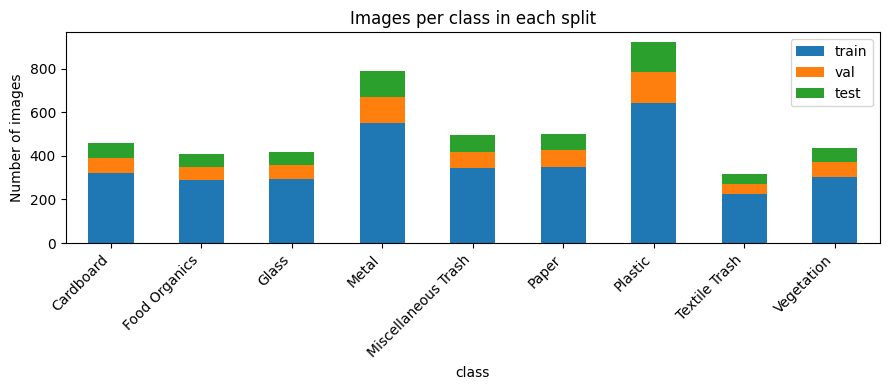

In [5]:
summary[["train", "val", "test"]].plot(kind="bar", stacked=True, figsize=(9, 4),
                                       title="Images per class in each split")
plt.ylabel("Number of images"); plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

## 4. Class weights (computed from the training split only)
Classes with fewer training images get larger weights, so the model is not rewarded for just predicting plastic and metal.

In [6]:
weights = compute_class_weight(
    class_weight="balanced", classes=np.arange(len(class_names)), y=train_df["label"].values)
class_weights = {int(i): float(w) for i, w in enumerate(weights)}

with open(SPLIT_DIR / "class_weights.json", "w") as f:
    json.dump(class_weights, f, indent=2)

for i, w in class_weights.items():
    print(f"{class_names[i]:<20} {w:.2f}")

Cardboard            1.15
Food Organics        1.28
Glass                1.25
Metal                0.67
Miscellaneous Trash  1.07
Paper                1.06
Plastic              0.57
Textile Trash        1.63
Vegetation           1.22


## 5. Input pipeline (tf.data)

Each image is decoded, resized to 224x224, and scaled with MobileNetV2 preprocessing to approximately -1 to 1. Augmentation is applied only to the training set. All datasets use parallel mapping and prefetching to improve throughput.


In [7]:
AUTOTUNE = tf.data.AUTOTUNE
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.1, value_range=(0, 255)),
    tf.keras.layers.RandomContrast(0.1),
], name="augmentation")

def load_image(filepath):
    img = tf.io.read_file(filepath)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return img

def make_dataset(frame, root, training=False, preprocess=True, batch_size=BATCH_SIZE):
    """frame needs 'path' (relative to root) and 'label' columns."""
    paths = [str(Path(root) / p) for p in frame["path"]]
    labels = frame["label"].values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda p, y: (load_image(p), y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    if preprocess:
        ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, DATA_DIR, training=True)
val_ds   = make_dataset(val_df,   DATA_DIR)
test_ds  = make_dataset(test_df,  DATA_DIR)

x, y = next(iter(train_ds))
print("Batch shape:", x.shape, "| pixel range: %.2f to %.2f" % (x.numpy().min(), x.numpy().max()))

Batch shape: (32, 224, 224, 3) | pixel range: -1.00 to 1.00


## 6. Visual check: original vs augmented
Always look at what the model will actually see. The augmented versions should still be recognizable.

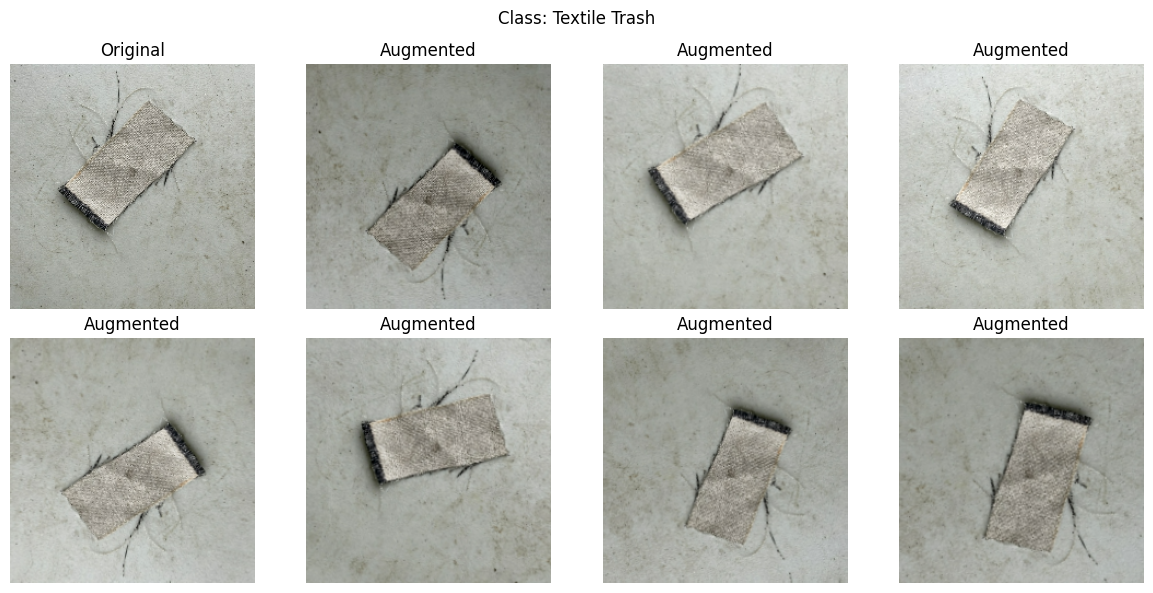

In [8]:
sample = train_df.sample(1, random_state=SEED).iloc[0]
orig = load_image(str(DATA_DIR / sample["path"]))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes[0, 0].imshow(orig.numpy().astype("uint8")); axes[0, 0].set_title("Original")
for ax in axes.flat[1:]:
    aug = augmentation(orig, training=True)
    ax.imshow(np.clip(aug.numpy(), 0, 255).astype("uint8")); ax.set_title("Augmented")
for ax in axes.flat: ax.axis("off")
plt.suptitle(f"Class: {sample['class']}"); plt.tight_layout(); plt.show()

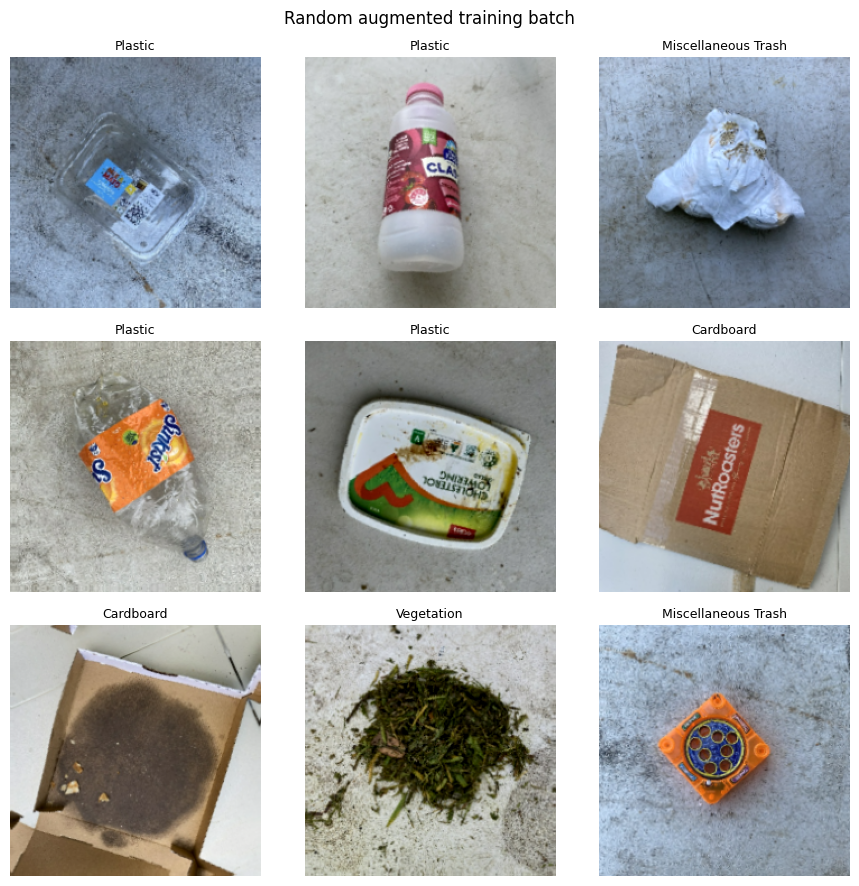

In [9]:
raw_batch_ds = make_dataset(train_df, DATA_DIR, training=True, preprocess=False, batch_size=9)
imgs, labs = next(iter(raw_batch_ds))

plt.figure(figsize=(9, 9))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(np.clip(imgs[i].numpy(), 0, 255).astype("uint8"))
    plt.title(class_names[int(labs[i])], fontsize=9); plt.axis("off")
plt.suptitle("Random augmented training batch"); plt.tight_layout(); plt.show()

## 7. Local Kigali test set (separate)

Put phone photos in `local_test/<ClassName>/*.jpg`, using the same folder names as RealWaste (for example, `Plastic` or `Food Organics`). These images must never be used for training or model selection. They provide a separate check of how well the model generalizes to locally collected Rwandan waste.

This cell creates `splits/local_test.csv` if the folder exists. If it does not exist, no local evaluation has been performed yet.


In [10]:
LOCAL_DIR = BASE_DIR / "local_test"

if LOCAL_DIR.exists():
    local_rows, unknown = [], []
    for d in sorted(p for p in LOCAL_DIR.iterdir() if p.is_dir()):
        if d.name not in class_to_idx:
            unknown.append(d.name); continue
        for p in sorted(d.iterdir()):
            if p.suffix.lower() in IMG_EXT:
                local_rows.append({"path": f"{d.name}/{p.name}", "class": d.name,
                                   "label": class_to_idx[d.name]})
    local_df = pd.DataFrame(local_rows)
    if unknown:
        print("WARNING: folders not matching a class name were skipped:", unknown)
    if len(local_df):
        local_df.to_csv(SPLIT_DIR / "local_test.csv", index=False)
        print(local_df["class"].value_counts().sort_index())
        local_test_ds = make_dataset(local_df, LOCAL_DIR)
    else:
        print("local_test/ exists but contains no images yet.")
else:
    print("No local_test/ folder yet. Add your Kigali photos later; nothing to do now.")

No local_test/ folder yet. Add your Kigali photos later; nothing to do now.


## 8. Notes for the report (fill in after running)

- Final split sizes and actual percentages (group-aware split is approximate):
- Why stratified group splitting is used, and the random seed (42):
- Number of perceptual groups and confirmation that no group crosses splits:
- Class weights: which classes receive the largest weights and why:
- Augmentations chosen and why:
- Known limitation: pHash can miss some visually similar images and can also flag visually similar but distinct items; inspect candidate groups and report the threshold used.
- Local Kigali test set: number of photos per class, collection method, and date. If no folder exists, explicitly state that local testing is pending.
